# 1. Measurements, errors and how to report a result

**Track:** core &nbsp;·&nbsp; **Prerequisites:** school algebra, a first look at Python

**Reading:** Taylor, ch. 1–2 · Bevington & Robinson, ch. 1 · Fornasini, ch.
1 and 4 · Rouaud, ch. I.A–C and I.I · JCGM 100:2008 (GUM), clauses 2–4

No measurement returns the true value of a quantity. A ruler has a finite
scale, a stopwatch is started a little late, a balance drifts with
temperature, and a simulation runs for a finite time. A number without a
statement of how far it can be trusted is therefore only half a result. The
other half is the *uncertainty*, and the purpose of this repository is to
learn how to obtain it, how to carry it through a calculation, and how to
state it honestly.

This first notebook sets up the vocabulary:

1. error and uncertainty are different things;
2. random and systematic effects behave differently;
3. an uncertainty can be evaluated from statistics (Type A) or from other
   knowledge (Type B);
4. independent contributions combine in quadrature;
5. a result is reported as *value ± uncertainty, unit*, with sensible rounding;
6. two results are compared in units of their combined uncertainty.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(1)

## 1.1 Error and uncertainty

The **error** of a measurement is the difference between the measured value
and the true value,

$$ \text{error} = x_\text{measured} - x_\text{true}. $$

It is a single number with a sign, and in a real experiment we never know
it, because we do not know $x_\text{true}$. (If we did, we would not need to
measure.)

The **uncertainty** $u$ is what we *can* state: a positive number that
measures the width of the range of values that could reasonably be
attributed to the quantity, given everything we know about the measurement.
We shall always use the **standard uncertainty**, which is an estimate of
the standard deviation of that range of values. Writing

$$ L = 12.34 \pm 0.05\ \text{mm} $$

then means: our best estimate is 12.34 mm, and the standard deviation that
describes our incomplete knowledge of $L$ is 0.05 mm. If the distribution is
close to normal, the true value lies within $\pm u$ of the estimate with a
probability of about 68 %, and within $\pm 2u$ with about 95 %.

The word "error" survives in many expressions (error bar, error analysis,
error propagation, standard error). In all of them it is the uncertainty
that is meant. An error in this sense is not a mistake: a perfectly executed
measurement still has an uncertainty.

## 1.2 Random and systematic effects

Repeat a measurement and the readings scatter. This is the **random** part
of the error: it changes sign and size unpredictably from one reading to
the next, and it averages towards zero when many readings are taken.

A **systematic** error is the part that stays the same when the measurement
is repeated: a ruler whose zero is worn, a thermometer that reads 0.4 K
high, a simulation box that is too small. Averaging does nothing to it.

The two parts correspond to two words that are often confused:

* **precision** is small random scatter;
* **accuracy** is closeness to the true value, which requires small random
  scatter *and* small systematic error.

The cell below simulates four instruments measuring the same quantity
(true value 10). Each panel shows 30 readings.

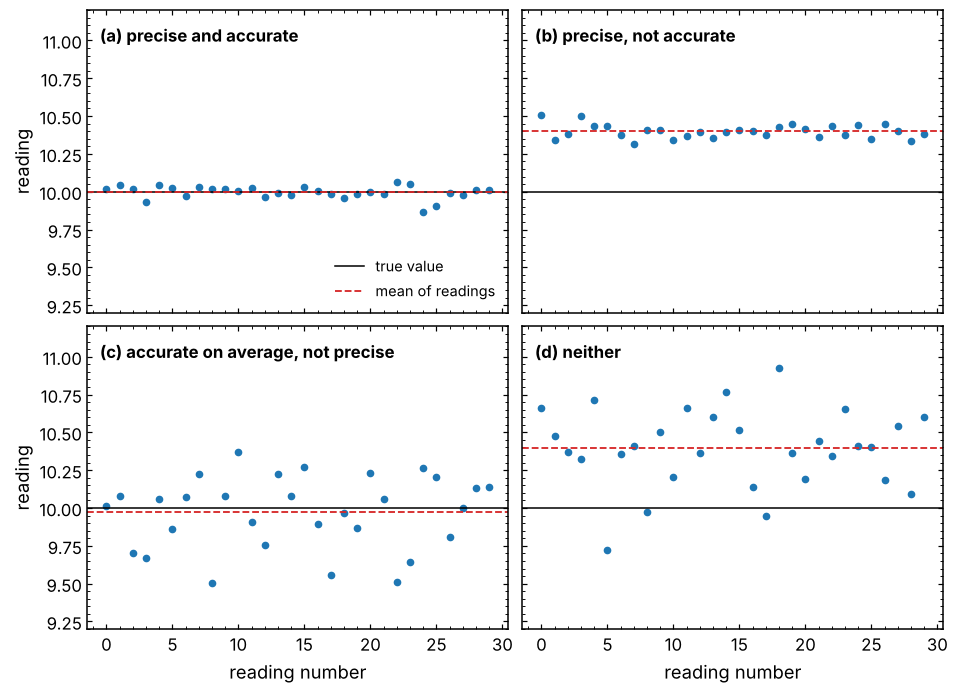

In [2]:
true_value = 10.0
cases = [("precise and accurate", 0.0, 0.05),
         ("precise, not accurate", 0.4, 0.05),
         ("accurate on average, not precise", 0.0, 0.30),
         ("neither", 0.4, 0.30)]

fig, axes = plt.subplots(2, 2, figsize=(8.6, 6.2), sharex=True, sharey=True)
for ax, (title, bias, sd), lab in zip(axes.flat, cases, "abcd"):
    x = true_value + bias + rng.normal(0, sd, 30)
    ax.plot(x, "o", ms=4, color="C0")
    ax.axhline(true_value, color="k", lw=1, label="true value")
    ax.axhline(x.mean(), color="C3", ls="--", lw=1.2, label="mean of readings")
    ax.set_ylim(9.2, 11.2)
    ep.panel_label(ax, f"({lab}) {title}")
axes[0, 0].legend(loc="lower right")
for ax in axes[1]:
    ax.set_xlabel("reading number")
for ax in axes[:, 0]:
    ax.set_ylabel("reading")
plt.show()

In panels (b) and (d) the mean of the readings (dashed line) sits away from
the true value, and no amount of repetition will move it. Notice also that
from the readings alone, panel (b) looks just as good as panel (a). A
systematic error cannot be seen in the scatter of the data. It has to be
found by thinking about the instrument and the method, by calibration
against a standard, or by measuring the same quantity in a different way.

Once a systematic error is known, we *correct* for it. What remains is the
uncertainty of the correction, and that uncertainty is treated like any
other contribution.

## 1.3 Two ways to evaluate an uncertainty

The international *Guide to the Expression of Uncertainty in Measurement*
(GUM) classifies uncertainties by how they are evaluated, not by where they
come from.

**Type A: from the statistics of repeated readings.** Take $N$ readings,
compute their standard deviation, and from it the uncertainty of the mean.
Chapter 4 is devoted to this.

**Type B: from any other information.** The resolution of a display, a
manufacturer's tolerance, a calibration certificate, a handbook value,
experience with the instrument. Here we must turn a statement such as "the
true value lies within $\pm a$" into a standard deviation.

### The rectangular distribution

Suppose all we know is that the value lies somewhere between $-a$ and $+a$
around the reading, with no reason to prefer any part of that interval. The
probability density is then flat, $p(x) = 1/(2a)$ for $|x| \le a$, and its
variance is

$$ u^2 = \int_{-a}^{a} x^2 \,\frac{1}{2a}\,\mathrm{d}x
       = \frac{1}{2a}\cdot\frac{2a^3}{3} = \frac{a^2}{3},
 \qquad\text{so}\qquad u = \frac{a}{\sqrt{3}} . $$

The most common case is a digital display. If the last digit steps by
$\delta$, the instrument has rounded the value to the nearest step, and the
rounding error lies within $\pm\delta/2$. With $a=\delta/2$,

$$ u_\text{resolution} = \frac{\delta}{2\sqrt{3}} = \frac{\delta}{\sqrt{12}} \approx 0.29\,\delta . $$

We can check this by rounding many random numbers.

In [3]:
delta = 0.01                               # display step, e.g. 0.01 g
values = rng.uniform(5.0, 6.0, 200_000)    # "true" values spread over many steps
displayed = np.round(values / delta) * delta
rounding_error = displayed - values

print(f"standard deviation of the rounding error : {rounding_error.std():.5f}")
print(f"delta / sqrt(12)                         : {delta / np.sqrt(12):.5f}")

standard deviation of the rounding error : 0.00289
delta / sqrt(12)                         : 0.00289


Other common Type B statements and their standard uncertainties:

| What is known | Distribution assumed | Standard uncertainty |
|---|---|---|
| "within $\pm a$", nothing more | rectangular | $a/\sqrt{3}$ |
| "within $\pm a$", values near the centre more likely | triangular | $a/\sqrt{6}$ |
| certificate quotes an expanded uncertainty $U$ with coverage factor $k$ | normal | $U/k$ |
| certificate quotes a "95 % confidence" interval $\pm U$ | normal | $U/1.96$ |

A Type B evaluation contains judgement. That is not a weakness, provided the
judgement is written down so that a reader can disagree with it.

## 1.4 Independent contributions add in quadrature

A reading is usually affected by several things at once, for instance
random scatter and finite resolution. If two error contributions
$\varepsilon_1$ and $\varepsilon_2$ are **independent**, with standard
deviations $u_1$ and $u_2$, the variance of their sum is

$$ \langle(\varepsilon_1+\varepsilon_2)^2\rangle
 = \langle\varepsilon_1^2\rangle + 2\langle\varepsilon_1\varepsilon_2\rangle + \langle\varepsilon_2^2\rangle
 = u_1^2 + u_2^2 , $$

because the cross term averages to zero: independent errors are as likely to
have opposite signs as the same sign. The combined standard uncertainty is
therefore

$$ u_c = \sqrt{u_1^2 + u_2^2} , $$

which is smaller than the plain sum $u_1 + u_2$. Adding linearly would
assume that both errors always push in the same direction, which is the
worst case and not the typical one.

In [4]:
u1, u2 = 0.30, 0.40
e1 = rng.normal(0, u1, 500_000)
e2 = rng.uniform(-u2 * np.sqrt(3), u2 * np.sqrt(3), 500_000)   # rectangular, std u2

print(f"simulated standard deviation of e1 + e2 : {(e1 + e2).std():.4f}")
print(f"quadrature sum sqrt(u1^2 + u2^2)        : {np.hypot(u1, u2):.4f}")
print(f"linear sum u1 + u2                      : {u1 + u2:.4f}")

simulated standard deviation of e1 + e2 : 0.4996
quadrature sum sqrt(u1^2 + u2^2)        : 0.5000
linear sum u1 + u2                      : 0.7000


The result does not depend on the shapes of the two distributions (one was
normal, the other rectangular), only on their standard deviations. This is
why the standard uncertainty is the natural currency of error analysis.

A consequence worth remembering: **the largest contribution dominates.** With
$u_1 = 1.0$ and $u_2 = 0.3$ the combination is $\sqrt{1.09} = 1.04$. Halving
the small contribution improves nothing; effort should go to the largest term.

## 1.5 Reporting a result

A result is reported as

$$ \text{quantity} = (\text{best estimate} \pm \text{standard uncertainty})\ \text{unit}. $$

**Rounding.** An uncertainty is itself known only roughly (Chapter 4 shows
that from ten readings it is good to about 25 %), so it is quoted to one or
two significant figures. The best estimate is then rounded to the same
decimal place. We use two figures throughout, which avoids a large rounding
step when the leading digit is 1 or 2.

| Raw calculator output | Reported |
|---|---|
| $9.81234 \pm 0.0234$ | $9.812 \pm 0.023$ |
| $8540.3 \pm 36.4$ | $8540 \pm 36$ |
| $0.000134561 \pm 0.0000021$ | $(1.346 \pm 0.021)\times10^{-4}$ |

The helper `format_result` applies these rules.

In [5]:
print(ep.format_result(9.81234, 0.0234, "m/s^2"))
print(ep.format_result(8540.3, 36.4, "kg/m^3"))
print(ep.format_result(1.34561e-4, 2.1e-6, "1/s"))
print(ep.format_concise(9.81234, 0.0234, "m/s^2"), "  (concise notation)")

9.812 ± 0.023 m/s^2
8540 ± 36 kg/m^3
(1.346 ± 0.021) × 10^-4 1/s
9.812(23) m/s^2   (concise notation)


In the concise notation the digits in brackets are the uncertainty in units
of the last decimal place quoted: $9.812(23)$ means $9.812 \pm 0.023$.

**Relative uncertainty.** The ratio $u/|x|$, usually given in per cent, says
how good a measurement is independently of units: $9.812 \pm 0.023$ has a
relative uncertainty of 0.23 %.

**Expanded uncertainty.** Some fields, engineering and metrology in
particular, quote $U = k\,u$ with a coverage factor $k = 2$, which for a
normal distribution corresponds to a level of confidence of about 95 %.
Either convention is acceptable. What is not acceptable is to leave the
reader guessing, so always say what the number after the $\pm$ is.

## 1.6 Do two results agree?

Two independent results $x_1 \pm u_1$ and $x_2 \pm u_2$ differ by
$x_1 - x_2$, and by Section 1.4 the uncertainty of that difference is
$\sqrt{u_1^2 + u_2^2}$. The natural measure of disagreement is the
difference in units of its own uncertainty,

$$ z = \frac{|x_1 - x_2|}{\sqrt{u_1^2 + u_2^2}} . $$

If only random effects are at work, $z < 1$ occurs about 68 % of the time
and $z < 2$ about 95 % of the time. As a working rule, $z \lesssim 2$ is
agreement, $z \gtrsim 3$ calls for an explanation, and in between one
should look harder. Comparison with an accepted value works the same way,
with $u_2$ the uncertainty of the accepted value (often negligible).

In [6]:
def discrepancy(x1, u1, x2, u2=0.0):
    """Difference between two results in units of its standard uncertainty."""
    return abs(x1 - x2) / np.hypot(u1, u2)

# two student groups measure the density of the same brass cylinder (kg/m^3)
print(f"group A vs group B : z = {discrepancy(8540, 36, 8478, 41):.2f}")
# group A against a handbook value for this alloy
print(f"group A vs handbook: z = {discrepancy(8540, 36, 8730, 10):.2f}")

group A vs group B : z = 1.14
group A vs handbook: z = 5.09


The two groups agree with each other ($z \approx 1.1$) and both disagree
with the handbook ($z \approx 5$). Agreement between groups using the same
method does not prove accuracy: both may share a systematic error. Here
the cylinder might contain a cavity, or might be a different alloy.

## Summary

* Error is unknown; uncertainty is our quantitative statement about it.
* Random effects scatter the readings and average out; systematic effects
  shift all readings together and do not.
* Type A uncertainties come from statistics, Type B from other knowledge;
  a bound $\pm a$ with no further information gives $u = a/\sqrt{3}$.
* Independent contributions combine as $u_c^2 = u_1^2 + u_2^2 + \dots$
* Report value, uncertainty and unit, with the uncertainty rounded to two
  significant figures, and say what the uncertainty means.

## Exercises

1. A digital thermometer shows 23.4 °C and the last digit never flickers.
   The manufacturer states an accuracy of ±0.5 °C. Give the standard
   uncertainty from the resolution, from the accuracy statement (assume
   rectangular), and combined. Which one matters?
2. Round and report: $1.23456 \pm 0.0789$; $299\,792.458 \pm 1.2$;
   $6.0221\times10^{23} \pm 3.1\times10^{20}$. Check with `ep.format_result`.
3. Three contributions of 0.5, 0.2 and 0.1 (same unit) are independent. What
   is the combined uncertainty? By how much does it fall if the smallest
   contribution is eliminated completely?
4. Modify the simulation of Section 1.2 so that the instrument has a bias
   that *drifts* linearly in time. Is this drift a random or a systematic
   effect? How could you detect it from the readings?

---

**Next:** [2. Measuring instruments](02_measuring_instruments.ipynb)